# 信贷违约预测

In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei']
# 修复中文环境下坐标轴负号‘-‘ 显示成方块的问题
plt.rcParams['axes.unicode_minus']=False
plt.rcParams['figure.figsize']=(10,5)
plt.rcParams['font.size']=10

df = pd.read_csv('credit card clients.csv',header=1)
df=df.rename(columns={'default payment next month':'default'})
df.shape
df.info() #查看每列：非空数量，数据类型
df.describe() #查看每列统计 均值 最值等


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   ID         30000 non-null  int64
 1   LIMIT_BAL  30000 non-null  int64
 2   SEX        30000 non-null  int64
 3   EDUCATION  30000 non-null  int64
 4   MARRIAGE   30000 non-null  int64
 5   AGE        30000 non-null  int64
 6   PAY_0      30000 non-null  int64
 7   PAY_2      30000 non-null  int64
 8   PAY_3      30000 non-null  int64
 9   PAY_4      30000 non-null  int64
 10  PAY_5      30000 non-null  int64
 11  PAY_6      30000 non-null  int64
 12  BILL_AMT1  30000 non-null  int64
 13  BILL_AMT2  30000 non-null  int64
 14  BILL_AMT3  30000 non-null  int64
 15  BILL_AMT4  30000 non-null  int64
 16  BILL_AMT5  30000 non-null  int64
 17  BILL_AMT6  30000 non-null  int64
 18  PAY_AMT1   30000 non-null  int64
 19  PAY_AMT2   30000 non-null  int64
 20  PAY_AMT3   30000 non-null  int64
 21  PAY_AMT4   3

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.853133,1.551867,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.790349,0.521970,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,0.000000,0.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,6.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


### 清洗类别脏数据

In [24]:

# 打印 这列 每种取值出现几次 看有没有混入0/5/6 这些数据字典里不存在的值
print(df['EDUCATION'].value_counts())
#把0/5/6（记录有误）替换成4 保证这列只有1 2 3 4
df['EDUCATION']=df['EDUCATION'].replace([0,5,6],4)
df.EDUCATION
# 打印 这列 每种取值出现几次 看有没有混入0 这些数据字典里不存在的值
print(df['MARRIAGE'].value_counts())
#把0记录有误）替换成3 保证这列只有1 2 3 
df['MARRIAGE']=df['MARRIAGE'].replace(0,3)
df.MARRIAGE


EDUCATION
2    14030
1    10585
3     4917
5      280
4      123
6       51
0       14
Name: count, dtype: int64
MARRIAGE
2    15964
1    13659
3      323
0       54
Name: count, dtype: int64


0        1
1        2
2        2
3        1
4        1
        ..
29995    1
29996    2
29997    2
29998    1
29999    1
Name: MARRIAGE, Length: 30000, dtype: int64

### 检查异常值
一些常识：

信用卡账单：正数=你欠银行多少钱。
负数 = 银行欠你的钱，产生场景：
退货退款
多还钱，账户溢缴款（你还多了，卡里剩余额）
这就是代码注释写“负数是退款情况”的来源，是银行业务常识


In [25]:
# 年龄是否都在合理区间
print(df['AGE'].min(),df['AGE'].max())
# 账单金额为负 = 溢缴款/退款，属正常业务现象，统计各月负值数量
print((df[[f'BILL_AMT{i}' for i in range (1,7)]]<0).sum())
pay_cols=[f'PAY_{i}' for i in [0,2,3,4,5,6]]
# 检查还款状态各列取值是否都在数据字典范围内
for c in pay_cols:
    print(c,sorted(df[c].unique()))


21 79
BILL_AMT1    590
BILL_AMT2    669
BILL_AMT3    655
BILL_AMT4    675
BILL_AMT5    655
BILL_AMT6    688
dtype: int64
PAY_0 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_2 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_3 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_4 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_5 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
PAY_6 [np.int64(-2), np.int64(-1), np.int64(0), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int

### 目标变量分布

In [26]:
# 统计违约（1） 和不违约（0）
print(df['default'].value_counts())
print(df['default'].mean())

df=df.drop('ID',axis=1) # ID只是编号，没有预测价值
df

default
0    23364
1     6636
Name: count, dtype: int64
0.2212


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000,1,3,1,39,0,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,150000,1,3,2,43,-1,-1,-1,-1,0,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,30000,1,2,2,37,4,3,2,-1,0,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,80000,1,3,1,41,1,-1,0,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


       count      mean
PAY_0                 
-2      2759  0.132294
-1      5686  0.167781
 0     14737  0.128113
 1      3688  0.339479
 2      2667  0.691414
 3       322  0.757764
 4        76  0.684211
 5        26  0.500000
 6        11  0.545455
 7         9  0.777778
 8        19  0.578947


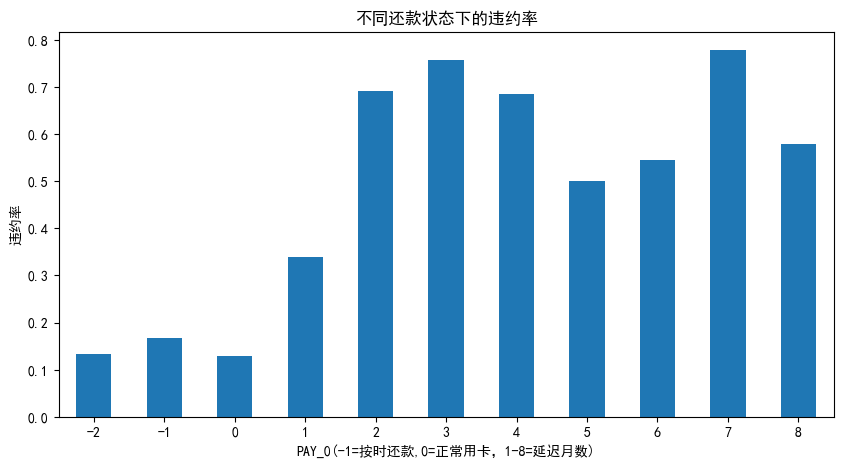

In [27]:
# 还款状态 和 违约率
# 按pay_0（上个月还款状态）分组 统计每组人数和违约率
# agg(['count','mean'])
pay0_group = df.groupby('PAY_0')['default'].agg(['count','mean'])
print(pay0_group)
pay0_group['mean'].plot(kind='bar')
plt.title('不同还款状态下的违约率')
plt.xlabel('PAY_0(-1=按时还款,0=正常用卡，1-8=延迟月数)')
plt.ylabel('违约率')
plt.xticks(rotation=0) 
plt.show()

### 结论：逾期2-3月的客户 违约率高达69-76% 即 上个月欠钱没还的 很大概率接下来依旧还不上 
可以看出 PAY_0对于会不会违约影响最大

             count      mean
PAY_0_GROUP                 
无逾期          23182  0.138340
逾期1-3月        6677  0.500225
逾期4月以上         141  0.631206


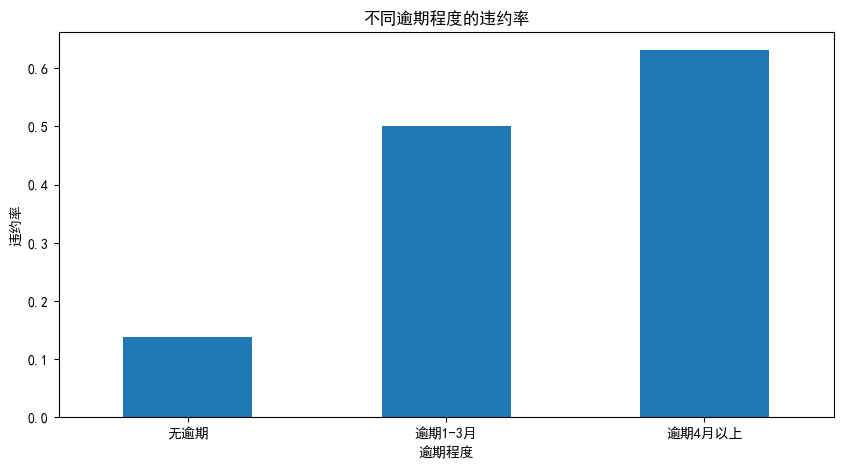

In [28]:
# PAY_0取值太散，归并成三档便于解读
def pay_bucket(x):
    if x<=0:
        return '无逾期'
    elif x<=3:
        return '逾期1-3月'
    else :
        return '逾期4月以上'
df['PAY_0_GROUP']=df['PAY_0'].apply(pay_bucket)

pay_group = df.groupby('PAY_0_GROUP')['default'].agg(['count','mean'])
print(pay_group)
pay_group['mean'].plot(kind='bar',rot=90)
plt.title('不同逾期程度的违约率')
plt.xlabel('逾期程度')
plt.ylabel('违约率')
plt.xticks(rotation=0) 
plt.show()

          count      mean
AGE_BIN                  
[21, 30)   9618  0.228426
[30, 40)  11238  0.202527
[40, 50)   6464  0.229734
[50, 60)   2341  0.248612
[60, 80)    339  0.283186


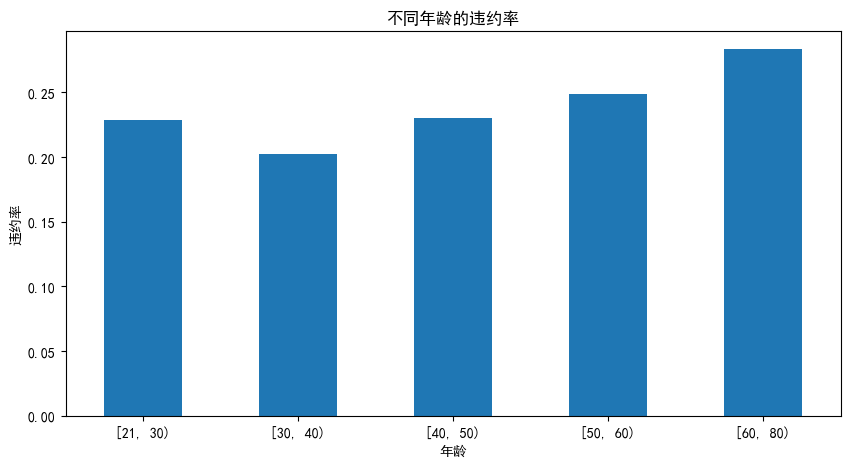

In [29]:
# 年龄与违约率
df['AGE_BIN']=pd.cut(df['AGE'],bins=[21,30,40,50,60,80],right=False)
# 按age年龄分组 统计每组人数和违约率
age_group = df.groupby('AGE_BIN',observed=True)['default'].agg(['count','mean'])
print(age_group)
age_group['mean'].plot(kind='bar',rot=90)
plt.title('不同年龄的违约率')
plt.xlabel('年龄')
plt.ylabel('违约率')
plt.xticks(rotation=0) 
plt.show()

                   count      mean
LIMIT_BIN                         
[10000, 50000)      4311  0.360705
[50000, 100000)     7139  0.260120
[100000, 200000)    7400  0.207703
[200000, 500000)   10222  0.154862
[500000, 1100000)    928  0.112069


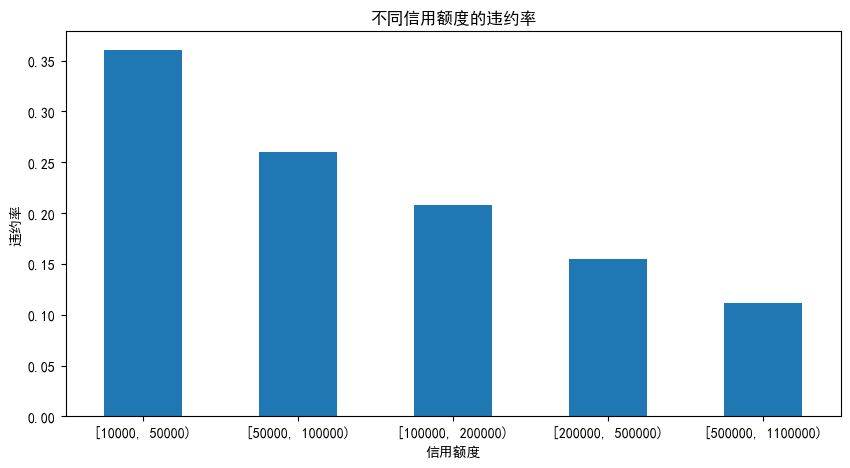

In [30]:
# 信用额度与违约率
df['LIMIT_BIN']=pd.cut(df['LIMIT_BAL'],bins=[10000,50000,100000,200000,500000,1100000],right=False)
# 统计每组人数和违约率
# agg(['count','mean'])  observed=True 只统计有人的组 空的跳过 避免笛卡尔积展开
limit_group = df.groupby('LIMIT_BIN',observed=True)['default'].agg(['count','mean'])
print(limit_group)
limit_group['mean'].plot(kind='bar')
plt.title('不同信用额度的违约率')
plt.xlabel('信用额度')
plt.ylabel('违约率')
plt.xticks(rotation=0) 
plt.show()

###  违约率成单调递减 信用额度越低违约率越高

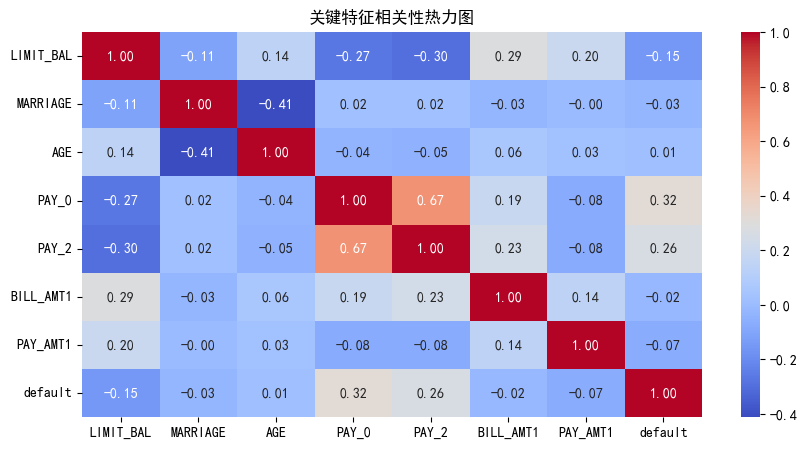

In [31]:
# 相关性热力图
import seaborn as sns
key_cols=['LIMIT_BAL','MARRIAGE','AGE','PAY_0','PAY_2','BILL_AMT1','PAY_AMT1','default']
corr= df[key_cols].corr()

sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f')
plt.title('关键特征相关性热力图')
plt.show()

### 结论： 可以看出PAY_0对default的影响最大

### 特征工程


In [32]:
# 1.还款率：BILL_AMT1<=0（没消费或溢缴款）时无意义，统一按1处理
df['BILL_RATE'] = np.where(
    df['BILL_AMT1']<=0,
    1,
    df['PAY_AMT1']/df['BILL_AMT1']
)
# 极端值截断到[0,2]，避免少数极端样本干扰模型
df['BILL_RATE']=df['BILL_RATE'].clip(0,2)


In [33]:
# 2.额度使用率：花得多、额度又低的人资金紧张度高
df['UTIL_RATE']=df['BILL_AMT1']/df['LIMIT_BAL']
df.groupby('default')[['BILL_RATE','UTIL_RATE']].mean()



,BILL_RATE,UTIL_RATE
default,,
0,0.414481,0.404876
1,0.316159,0.490297


### 可以看出 不违约的客户还款率更高； 违约客户占用的额度更高，资金压力大 易违约

In [34]:
df.groupby('default')[['BILL_RATE','UTIL_RATE']].median()

,BILL_RATE,UTIL_RATE
default,,
0,0.079989,0.267498
1,0.058661,0.492875


In [35]:
df[['BILL_RATE','UTIL_RATE']].describe()

,BILL_RATE,UTIL_RATE
count,30000.000000,30000.000000
mean,0.392732,0.423771
std,0.576942,0.411462
min,0.000000,-0.619892
25%,0.038864,0.022032
50%,0.074452,0.313994
75%,0.640028,0.829843
max,2.000000,6.455300


### 建模

In [36]:
# 准备建模材料
# y--要预测的目标
y=df['default']
# 只挑了前面EDA验证过有区分度的9个特征
features=['LIMIT_BAL','SEX','EDUCATION','MARRIAGE','AGE','PAY_0','PAY_2','BILL_RATE','UTIL_RATE']
X=df[features]
# 看一眼形状 X是3万行9列 y是3万个0/1
print(X.shape,y.shape)

(30000, 9) (30000,)


In [37]:
## 分数据
from sklearn.model_selection import train_test_split

# stratify=y 分层抽样，保证训练/测试集违约率和原始数据一致
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.3,random_state=42,stratify=y
)
print('训练集违约率：',y_train.mean())
print('测试集违约率：',y_test.mean())

训练集违约率： 0.2211904761904762
测试集违约率： 0.2212222222222222


In [38]:
## 训练模型
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# 模型A 逻辑回归 不开权重
lr=LogisticRegression(max_iter=1000)
lr.fit(X_train,y_train)
# 模型B 逻辑回归 开权重
lr_bar=LogisticRegression(max_iter=1000,class_weight='balanced')
lr_bar.fit(X_train,y_train)
# 模型C 随机森林 对比实验
rf=RandomForestClassifier(n_estimators=100,random_state=42)
rf.fit(X_train,y_train)

d:\dataA\Lib\site-packages\sklearn\linear_model\_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


### 出现警告 说 没算尽兴 逻辑回归做题做一半，（迭代次数达到上限） 暗示模型没达到最佳状态
 特征单位差太远了 -- LIMIT_BAL是10万级别，BILL_RATE是0-2的小数

 因此做了标准化

In [39]:
from sklearn.preprocessing import StandardScaler

# 训练前先标准化（把每个特征都压到“平均0，标准差1”的尺度上）
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)
#重新训练逻辑回归
lr.fit(X_train_scaled,y_train)
lr_bar.fit(X_train_scaled,y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,'balanced'
,random_state,None
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


In [40]:
# 模型验收：AUC
from sklearn.metrics import roc_auc_score
auc_lr=roc_auc_score(y_test,lr.predict_proba(X_test_scaled)[:,1])
auc_lr_bal=roc_auc_score(y_test,lr_bar.predict_proba(X_test_scaled)[:,1])
auc_rf=roc_auc_score(y_test,rf.predict_proba(X_test)[:,1])

print(f'逻辑回归(无权重): AUC={auc_lr:.4f}')
print(f'逻辑回归: AUC={auc_lr_bal:.4f}')
print(f'随机森林: AUC={auc_rf:.4f}')

逻辑回归(无权重): AUC=0.7138
逻辑回归: AUC=0.7142
随机森林: AUC=0.7353


In [41]:
# 业务结论
 
# 1.用逻辑回归，给测试集9000人打‘违约分概率’
score=lr.predict_proba(X_test_scaled)[:,1]
# 2.模拟审批策略：把分数最高的30%（=最可能违约的30%）拒之门外
threshold=np.quantile(score,0.7)
approved=y_test[score<=threshold]
print(f'整体违约率：{y_test.mean():.3f}')
print(f'拒绝最低分30%后违约率：{approved.mean():.3f}')
print(f'坏账风险下降了：{(1-approved.mean()/y_test.mean())*100:.1f}')

整体违约率：0.221
拒绝最低分30%后违约率：0.135
坏账风险下降了：39.0


In [42]:
coef = pd.Series(lr.coef_[0], index=features).sort_values()
print(coef)

LIMIT_BAL   -0.306063
UTIL_RATE   -0.109873
MARRIAGE    -0.087990
EDUCATION   -0.084833
SEX         -0.053491
AGE          0.055867
BILL_RATE    0.222075
PAY_2        0.313662
PAY_0        0.682104
dtype: float64


KS值：0.360
判断：KS≥0.3，模型区分度良好，可用于业务审批策略


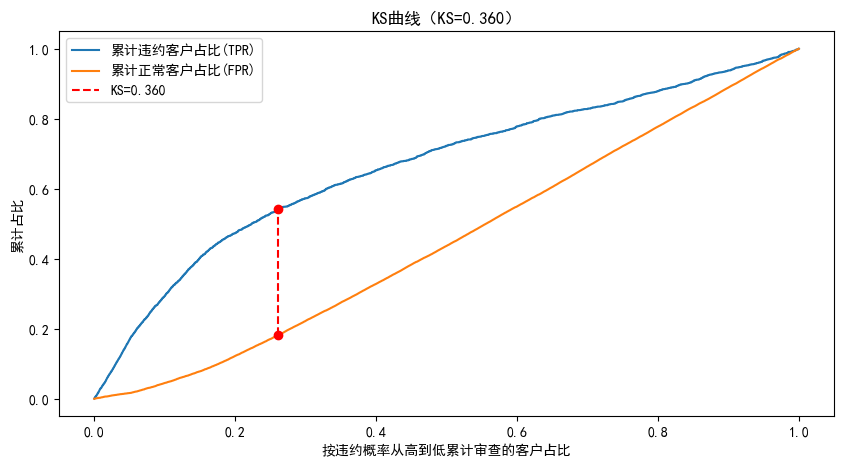

In [43]:
# KS：风控常用指标。按违约概率排序后累加，TPR与FPR两条曲线的最大差距就是KS，
# 衡量模型把坏客户排到前面的能力
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, score)
ks_value = (tpr - fpr).max()
print(f'KS值：{ks_value:.3f}')

# 经验标准（风控行业常用）：KS<0.2区分度弱；0.2~0.3可用；0.3~0.5区分度良好
if ks_value >= 0.3:
    print('判断：KS≥0.3，模型区分度良好，可用于业务审批策略')
elif ks_value >= 0.2:
    print('判断：KS在0.2~0.3之间，模型有一定区分度，但效果一般')
else:
    print('判断：KS<0.2，模型区分度太弱，不建议使用')

# KS曲线
df_ks=pd.DataFrame({'score':score,'y':np.asarray(y_test)})
df_ks=df_ks.sort_values('score',ascending=False).reset_index(drop=True)
df_ks['cum_bad']=df_ks['y'].cumsum()/df_ks['y'].sum()       # 累计抓到的违约客户占比
df_ks['cum_good']=(1-df_ks['y']).cumsum()/(1-df_ks['y']).sum() # 累计经过的正常客户占比
df_ks['x']=np.arange(1,len(df_ks)+1)/len(df_ks)
gap=df_ks['cum_bad']-df_ks['cum_good']
best=gap.idxmax()  # 两条线差距最大的位置
plt.plot(df_ks['x'],df_ks['cum_bad'],label='累计违约客户占比(TPR)')
plt.plot(df_ks['x'],df_ks['cum_good'],label='累计正常客户占比(FPR)')
plt.scatter([df_ks.loc[best,'x']],[df_ks.loc[best,'cum_bad']],color='red',zorder=5)
plt.scatter([df_ks.loc[best,'x']],[df_ks.loc[best,'cum_good']],color='red',zorder=5)
plt.vlines(df_ks.loc[best,'x'],df_ks.loc[best,'cum_good'],df_ks.loc[best,'cum_bad'],
           colors='red',linestyles='--',label=f'KS={ks_value:.3f}')
plt.title(f'KS曲线（KS={ks_value:.3f}）')
plt.xlabel('按违约概率从高到低累计审查的客户占比')
plt.ylabel('累计占比')
plt.legend()
plt.show()